[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/04-analyst-executor-loop/04-analyst-executor-loop.ipynb)

# 04 · The Analyst–Executor Loop

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*
*Disclosure: this notebook and its text were produced with AI assistance; every figure in it is checked against the recorded run evidence in this folder before release.*

## What you will learn
- Pair an analyst that drafts code with an executor that runs it in a teaching-only in-process executor — and returns the real error, verbatim.
- Read an error as curriculum: the revision exists because the failure was legible.
- Terminate on a typed signal or a budget — never on hope.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and the evidence section compares them with the recorded run evidence shipped in this repository. Work the exercises with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 0 · Why this matters — the market in numbers

- **The market:** enterprise agentic AI software is forecast from **$2.58B (2024) to $24.5B (2030)**, a 46.2% CAGR — Grand View Research, Enterprise Agentic AI Market Report 2025–2030.
- **The adoption wave:** Gartner (Aug 2025) predicts **40% of enterprise applications will feature task-specific AI agents by end of 2026**, up from under 5% in 2025.
- **The failure curve:** Gartner (Jun 2025) predicts **over 40% of agentic AI projects will be cancelled by end of 2027** — on escalating costs, unclear business value and inadequate risk controls.

Analyst agents fail in two ways — loudly, in errors a loop can learn from, or silently, in wrong answers nobody prices. This POC's answer is a loop that types every failure (ERROR / EMPTY / SUCCESS) and makes the error itself the curriculum.

*Sources: Grand View Research (2025); Gartner press releases, Jun 2025 and 2025-08-26. These are market forecasts, cited as market data — the results inside this notebook are a scripted demonstration and are labelled ILLUSTRATIVE.*

## 1 · The idea

**Idea:** Find the leaks in a household budget from a transaction export, with an analyst that writes code and an executor that runs it — iterating on real output and real errors.
**Build steps:** (1) Two roles share only a transcript (`kit/transcript.py`). (2) The Analyst drafts code per question; the Executor runs it in a teaching-only in-process executor and returns output or the verbatim error as a message. (3) Failed attempts stay in the transcript — the Analyst's revisions exist because the errors were legible. (4) Terminate on the signal ANALYSIS COMPLETE or the turn cap.
**Guardrail:** Education, not financial advice. Synthetic data only; the executor here is teaching-only (in-process exec, restricted builtins over an in-memory copy) — a restricted builtin set is not an isolation boundary; production means an isolated runner.
**Win condition:** Findings trace to actual rows of the export, not generic money tips; every error in the run is printed, read, and answered by a revision.
Data: synthetic only. Model: deterministic stub, no live model.

## 2 · How it is built

Built: `poc/analyst_executor.py` using `kit/transcript.py` (TranscriptStore) and `kit/termination.py` (signal + cap).
Design: Analyst code → in-process exec (restricted builtins, only the copied export visible - a teaching executor, not an isolation boundary) → output or verbatim error returned as a transcript message → Analyst revises. Five attempts: a KeyError on an assumed column name, the schema-print recovery, the corrected totals, an empty result from a wrong category name, and the corrected leak query.
Run: `python3 poc/analyst_executor.py` → `runs/run-01.txt` + `runs/transcript-01.jsonl`.

**Execution flow** (version of record: `diagrams/TECHNICAL-FLOWS.md`):

```mermaid
%%{init: {"flowchart": {"nodeSpacing": 28, "rankSpacing": 44, "padding": 12}}}%%
flowchart LR
    A(["1 · Load transactions<br/>22 rows · data/transactions.csv"]):::io --> B["2 · Analyst<br/>writes the attempt"]:::proc
    B --> C["3 · Executor runs it<br/>teaching-only, in-process"]:::proc
    C --> D{"4 · Outcome?"}:::decision
    D -->|ERROR| B
    D -->|EMPTY| B
    D -->|SUCCESS| E["5 · Finding<br/>traced to actual rows"]:::proc
    E --> F(["6 · Termination<br/>typed signal · budget in-loop"]):::metric
    classDef io fill:#1A1A2E,stroke:#C9A227,stroke-width:2px,color:#FFFFFF;
    classDef proc fill:#E6F4F6,stroke:#1B9AAA,stroke-width:1.5px,color:#123B40;
    classDef decision fill:#FBF3D9,stroke:#C9A227,stroke-width:2px,color:#5A4A00;
    classDef warn fill:#FBE9E7,stroke:#C1666B,stroke-width:1.5px,color:#6E2B26;
    classDef metric fill:#1B9AAA,stroke:#146B76,stroke-width:2px,color:#FFFFFF;
```

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

for _d in ("data", "runs"):
    Path(_d).mkdir(exist_ok=True)
_input_path = Path("data/transactions.csv")
if not _input_path.exists():
    _input_path.write_text('month,category,amount\n2026-01,groceries,82.0\n2026-01,groceries,82.0\n2026-01,groceries,82.0\n2026-01,groceries,82.0\n2026-01,coffee-subscription,14.99\n2026-01,coffee-subscription,14.99\n2026-02,groceries,91.0\n2026-02,groceries,91.0\n2026-02,groceries,91.0\n2026-02,groceries,91.0\n2026-02,coffee-subscription,14.99\n2026-02,coffee-subscription,14.99\n2026-02,gym-unused,39.0\n2026-03,groceries,88.0\n2026-03,groceries,88.0\n2026-03,groceries,88.0\n2026-03,groceries,88.0\n2026-03,coffee-subscription,14.99\n2026-03,coffee-subscription,14.99\n2026-03,coffee-subscription,14.99\n2026-03,gym-unused,39.0\n2026-03,streaming-b,11.99\n', encoding="utf-8")
    print('input data materialized from the copy embedded in this notebook (in the repository it ships as data/transactions.csv)')

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The shared kit (inlined)

The repository keeps these primitives once, in `kit/`, and every POC reuses them. They are inlined here so this notebook runs standalone in Colab — the code is identical to the kit source.

In [2]:
# --- from the shared kit: kit/transcript.py ---
"""Transcript store: the transcript IS the state (POC 02 pattern)."""
import json
from pathlib import Path

class TranscriptStore:
    def __init__(self):
        self.messages = []
    def append(self, speaker, kind, content):
        msg = {"turn": len(self.messages) + 1, "speaker": speaker, "kind": kind, "content": content}
        self.messages.append(msg)
        return msg
    def save_jsonl(self, path):
        Path(path).write_text("\n".join(json.dumps(m) for m in self.messages) + "\n")
    def __len__(self):
        return len(self.messages)

# --- from the shared kit: kit/termination.py ---
"""Termination caps and typed exits."""
class Termination:
    def __init__(self, max_turns=20, signal=None):
        self.max_turns = max_turns
        self.signal = signal
        self.turns = 0
    def check(self, text):
        self.turns += 1
        if self.signal and text.strip().endswith(self.signal):
            return "SIGNAL"
        if self.turns >= self.max_turns:
            return "CAP_TURNS"
        return None

## 5 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline; the `__main__` guard is replaced by the Run cell below).

In [3]:
"""POC 04 - The Analyst-Executor Loop.
An Analyst drafts code for a question; an Executor runs it in-process
and returns the real output - or the real error - as a message. The
Analyst reads the error and revises. The conversation is the control
flow: there is no retry table, the error is the curriculum.
Deterministic stub: no live model. Data: synthetic transactions only,
read from data/transactions.csv - the data file is the single source
for the run; every figure below is computed from it.
Executor honesty note: the executor is a TEACHING-ONLY in-process
exec with a restricted builtin set over an in-memory copy of the data.
A restricted builtin set is NOT an isolation boundary - never run
untrusted code or real data through it. A production runner isolates
execution properly (separate process/container); this one does not.
"""
import csv
import sys
from pathlib import Path

SAFE_BUILTINS = {"sum": sum, "len": len, "round": round, "sorted": sorted,
                 "min": min, "max": max, "print": print}


def load_rows(path):
    """Load the transaction export (month, category, amount) from CSV."""
    with open(path, newline="", encoding="utf-8") as fh:
        return [{"month": r["month"], "category": r["category"],
                 "amount": float(r["amount"])} for r in csv.DictReader(fh)]


def run_executor(code, rows):
    """Run analyst code with only `rows` and safe builtins visible.
    Returns (ok, result_or_error_message). Errors come back as the
    exception type and message - legible errors are the point of the
    loop. Teaching-only: this is not a sandbox (see module docstring)."""
    namespace = {"rows": [dict(r) for r in rows], "__builtins__": SAFE_BUILTINS}
    try:
        exec(code, namespace)
        return True, namespace.get("result")
    except Exception as exc:  # the error IS the message back to the analyst
        return False, f"{type(exc).__name__}: {exc}"


# The analyst's attempts, in order. Attempts 1 and 4 fail legibly; the
# analyst's revisions (2, 3, 5) exist only because the errors were read.
# Attempts are selected by their question text, never by list index, so
# adding or removing an attempt cannot break the finding.
ATTEMPTS = [
    ("Total spend by category",
     "result = {}\nfor r in rows:\n    result[r['category']] = round(result.get(r['category'], 0) + r['amt'], 2)"),
    ("Print the schema first (the recovery habit)",
     "result = {'columns': sorted(rows[0].keys()), 'row_count': len(rows)}"),
    ("Total spend by category (revised: key is 'amount')",
     "result = {}\nfor r in rows:\n    result[r['category']] = round(result.get(r['category'], 0) + r['amount'], 2)"),
    ("Monthly charges for category 'gym'",
     "result = [r for r in rows if r['category'] == 'gym']"),
    ("Monthly charges for 'gym-unused' (exact name from the totals)",
     "result = [(r['month'], r['amount']) for r in rows if r['category'] == 'gym-unused']"),
]

TOTALS_QUESTION = "Total spend by category (revised: key is 'amount')"
LEAK_QUESTION = "Monthly charges for 'gym-unused' (exact name from the totals)"


def analyse(rows, max_turns=20):
    """Run the attempt loop over `rows`. The turn budget is enforced
    inside the loop: when the cap is hit the loop stops and records
    CAP_TURNS instead of completing. Returns (transcript, attempts,
    finding, terminated_by)."""
    t = TranscriptStore()
    term = Termination(max_turns=max_turns, signal="ANALYSIS COMPLETE")
    attempts = []
    terminated_by = None
    for i, (question, code) in enumerate(ATTEMPTS, start=1):
        t.append("Analyst", "code", f"Attempt {i} - {question}: {code.splitlines()[0]} ...")
        ok, out = run_executor(code, rows)
        if not ok:
            outcome = "ERROR"
            t.append("Executor", "error", out)
        elif out == [] or out == {}:
            outcome = "EMPTY"
            t.append("Executor", "result", "[] (no rows matched - the question, not the code, is wrong)")
        else:
            outcome = "SUCCESS"
            t.append("Executor", "result", str(out))
        attempts.append({"attempt": i, "stage": question, "outcome": outcome})
        if term.check(outcome) == "CAP_TURNS":
            terminated_by = "CAP_TURNS"
            t.append("Executor", "termination",
                     f"turn budget {max_turns} reached - loop stopped mid-run")
            break
    by_question = {q: c for q, c in ATTEMPTS}
    if LEAK_QUESTION in by_question and TOTALS_QUESTION in by_question:
        leak_ok, leak_rows = run_executor(by_question[LEAK_QUESTION], rows)
        leak_total = round(sum(a for _, a in leak_rows), 2) if leak_ok else 0.0
        months = ", ".join(sorted({m for m, _ in leak_rows})) if leak_ok else ""
        finding = (f"FINDING: gym-unused totals ${leak_total:.2f} across {months} with no activity "
                   "category in the export - the loop's top leak, traced to actual rows.")
    else:
        finding = "FINDING: unavailable - the totals/leak attempts were removed from this run."
    t.append("Analyst", "finding", finding)
    if terminated_by is None:
        final = "ANALYSIS COMPLETE"
        t.append("Analyst", "signal", final)
        terminated_by = term.check(final) or "SIGNAL"
    return t, attempts, finding, terminated_by


def main():
    base = Path(".")  # notebook context: this folder (the notebook folder in the repo)
    rows = load_rows(base / "data" / "transactions.csv")
    t, attempts, finding, terminated_by = analyse(rows)
    out_path = base / "runs" / "transcript-01.jsonl"
    t.save_jsonl(out_path)
    with open(base / "runs" / "attempts.csv", "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh)
        w.writerow(["attempt", "stage", "outcome"])
        for a in attempts:
            w.writerow([a["attempt"], a["stage"], a["outcome"]])
    errors = sum(1 for a in attempts if a["outcome"] == "ERROR")
    empty = sum(1 for a in attempts if a["outcome"] == "EMPTY")
    successes = sum(1 for a in attempts if a["outcome"] == "SUCCESS")
    for a in attempts:
        print(f"attempt {a['attempt']}: {a['outcome']} - {a['stage']}")
    print(f"attempts={len(attempts)} errors={errors} empty={empty} successes={successes} "
          f"transcript={out_path.name}")
    print(finding)
    print("TERMINATION:", terminated_by)

## 6 · Run it

In [4]:
main()

attempt 1: ERROR - Total spend by category
attempt 2: SUCCESS - Print the schema first (the recovery habit)
attempt 3: SUCCESS - Total spend by category (revised: key is 'amount')
attempt 4: EMPTY - Monthly charges for category 'gym'
attempt 5: SUCCESS - Monthly charges for 'gym-unused' (exact name from the totals)
attempts=5 errors=1 empty=1 successes=3 transcript=transcript-01.jsonl
FINDING: gym-unused totals $78.00 across 2026-02, 2026-03 with no activity category in the export - the loop's top leak, traced to actual rows.
TERMINATION: SIGNAL


## 7 · See the evidence

The chart is drawn from the run's own results table (`runs/attempts.csv` in the repository, written by the Run cell above). The recorded table is embedded below as a clearly labelled fallback for readers who have not run the cells.

chart data: this session's run (runs/attempts.csv, written by the Run cell above)
 attempt                                                         stage outcome
       1                                       Total spend by category   ERROR
       2                   Print the schema first (the recovery habit) SUCCESS
       3            Total spend by category (revised: key is 'amount') SUCCESS
       4                            Monthly charges for category 'gym'   EMPTY
       5 Monthly charges for 'gym-unused' (exact name from the totals) SUCCESS


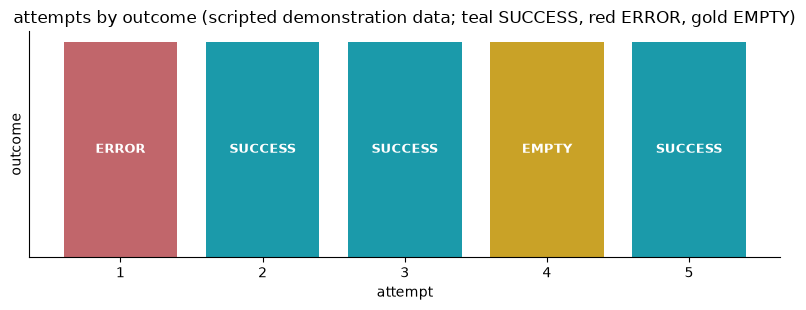

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep library warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """attempt,stage,outcome
1,Total spend by category,ERROR
2,Print the schema first (the recovery habit),SUCCESS
3,Total spend by category (revised: key is 'amount'),SUCCESS
4,Monthly charges for category 'gym',EMPTY
5,Monthly charges for 'gym-unused' (exact name from the totals),SUCCESS"""

csv_file = Path("runs/attempts.csv")
if csv_file.exists():
    text = csv_file.read_text()
    print("chart data: this session's run (runs/attempts.csv, written by the Run cell above)")
else:
    text = RECORDED_CSV
    print("chart data: the RECORDED run shipped in the repository (the Run cell has not been executed in this session)")
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "attempts"
if CHART_MODE == "attempts":
    colors = ["#C1666B" if o == "ERROR" else ("#C9A227" if o == "EMPTY" else "#1B9AAA") for o in df["outcome"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    bars = ax.bar(df["attempt"], [1] * len(df), color=colors)
    for rect, outcome in zip(bars, df["outcome"]):
        ax.text(rect.get_x() + rect.get_width() / 2, 0.5, outcome, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_yticks([]); ax.set_xlabel("attempt"); ax.set_ylabel("outcome")
    ax.set_title("attempts by outcome (scripted demonstration data; teal SUCCESS, red ERROR, gold EMPTY)")
elif CHART_MODE == "routing":
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["agent_turns"], width=0.4, color="#1B9AAA", label="agent turns")
    ax.bar([i + 0.2 for i in x], df["total_calls"], width=0.4, color="#C9A227", label="total calls")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["mode"]); ax.set_ylabel("count"); ax.legend()
    ax.set_title("turns and total calls by routing mode (scripted demonstration data)")
else:  # debate
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["pro_strength"], width=0.4, color="#1B9AAA", label="pro strength")
    ax.bar([i + 0.2 for i in x], df["con_strength"], width=0.4, color="#C1666B", label="con strength")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["claim"] + " (" + df["verdict"] + ")")
    ax.set_ylabel("scripted argument strength"); ax.legend()
    ax.set_title("debate strength by claim (scripted demonstration data)")
for _a in [ax]:
    _a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 8 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.txt` (executed 2026-10-26, deterministic stub, synthetic transactions); the analyst's attempts are scripted for the lesson, so the attempt outcomes illustrate the pattern — against a live model this is where measured attempt data would land.

- Attempts: 5 — 3 SUCCESS, 1 ERROR (KeyError: 'amt' — an assumed column name, returned verbatim and answered by printing the schema), 1 EMPTY (category 'gym' matched no rows; the exact name 'gym-unused' came from the totals table).
- Finding: gym-unused totals $78.00 across 2026-02, 2026-03 with no activity category in the export — computed from the export rows by the corrected code.
- Termination: ANALYSIS COMPLETE → TERMINATION: SIGNAL.
- Input: `data/transactions.csv` - the export the run reads. Results: `runs/attempts.csv`, written by the run itself (ILLUSTRATIVE). Chart: drawn in the notebook from the run's own results table (ILLUSTRATIVE).

## 9 · Exercises

1. Add a sixth attempt of your own (for example: average grocery spend per month). Predict whether it succeeds first try — then check what the transcript says about your prediction.
2. Break the executor honestly: draft code that tries to open a file. What error comes back, and is it legible enough to revise from? A restricted builtin list is not an isolation boundary — what would a production runner add?
3. Remove the schema-print attempt and re-run: the run must still complete and the finding must still compute (attempts are selected by question, never by position — tests/test_perturbation.py proves it). Which attempt's rationale disappears, and what does that teach about the order in which a loop should ask its questions?

## 10 · Recap

A fixed pipeline knows only the questions it was built with. The loop earns its keep the first time reality disagrees with an assumption — provided the error comes back whole. Make errors legible, cap everything, and let the conversation be the control flow.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*